# 01 · 認識 PBMC3k 單細胞資料

一列是一個細胞，一欄是一個基因；原始值是測到的 RNA 計數。這個 Notebook 逐步完成資料探索、QC、正規化、PCA 與 UMAP，使用固定 seed 42。

資料由 Scanpy 首次連線下載（約 6 MB），之後使用本機快取。原始資料沒有獨立的 cell-type 標籤。這裡的全資料探索不能直接用來擬合模型前處理；Notebook 02 會重新讀原始 counts。

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "請從專案根目錄或 notebooks/ 啟動"
sys.path.insert(0, str(ROOT))
for key, folder in [("MPLCONFIGDIR", "matplotlib"), ("NUMBA_CACHE_DIR", "numba"), ("XDG_CACHE_HOME", "")]:
    os.environ.setdefault(key, str(ROOT / ".cache" / folder))

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import display, Image
from singlecell_baseline.data import DataConfig, load_pbmc3k, quality_control

FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
config = DataConfig()
from importlib.metadata import version
print("Python:", sys.version.split()[0], "Scanpy:", version("scanpy"))

Python: 3.11.2 Scanpy: 1.11.5


## 1. 查看資料軸與 metadata

`X` 是細胞 × 基因矩陣。CSR 稀疏矩陣只儲存非零元素，適合大量零值的 scRNA-seq 資料；零值不代表基因在生物學上必定完全不表達。`obs` 對應細胞，`var` 對應基因。

In [2]:
raw = load_pbmc3k(ROOT / "data" / "raw")
print(raw)
print("矩陣型別:", type(raw.X).__name__, "形狀:", raw.shape, "dtype:", raw.X.dtype)
print("obs 欄位:", raw.obs.columns.tolist())
print("var 欄位:", raw.var.columns.tolist())
display(raw.obs.head(), raw.var.head())
# 僅將小切片轉成 dense DataFrame，避免將完整大矩陣轉成 dense。
common_genes = np.asarray(raw.X.sum(axis=0)).ravel().argsort()[-8:]
display(raw[:5, common_genes].to_df())

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
矩陣型別: csr_matrix 形狀: (2700, 32738) dtype: float32
obs 欄位: []
var 欄位: ['gene_ids']


""
index
AAACATACAACCAC-1
AAACATTGAGCTAC-1
AAACATTGATCAGC-1
AAACCGTGCTTCCG-1
AAACCGTGTATGCG-1


,gene_ids
index,
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945


index,RPS2,FTL,RPL13A,RPL13,RPL10,B2M,TMSB4X,MALAT1
index,,,,,,,,
AAACATACAACCAC-1,44.0,12.0,37.0,29.0,34.0,76.0,47.0,49.0
AAACATTGAGCTAC-1,97.0,10.0,81.0,45.0,92.0,75.0,62.0,142.0
AAACATTGATCAGC-1,30.0,8.0,40.0,16.0,49.0,69.0,117.0,171.0
AAACCGTGCTTCCG-1,17.0,78.0,16.0,15.0,22.0,41.0,114.0,11.0
AAACCGTGTATGCG-1,4.0,18.0,1.0,4.0,8.0,35.0,21.0,22.0


## 2. 品質控制（QC）

每個細胞的總 counts、偵測到的基因數、粒線體基因 counts 比例，可協助發現低品質細胞。`MT-` 開頭是此人類資料的粒線體基因標記。

初版沿用 PBMC 教學的固定門檻：至少 200 且少於 2,500 個基因，粒線體 counts 比例低於 5%。圖上的紅線顯示門檻；它們是起步設定，並非通用的品質真值，也不能保證排除所有 doublets。

,total_counts,n_genes_by_counts,pct_counts_mt
count,2700.000000,2700.000000,2700.000000
mean,2366.900391,846.994074,2.215132
std,1094.262085,282.104964,1.165438
min,548.000000,212.000000,0.000000
1%,658.930000,326.000000,0.593839
50%,2197.000000,817.000000,2.029639
99%,5928.620000,1749.010000,5.876420
max,15844.000000,3422.000000,22.569027


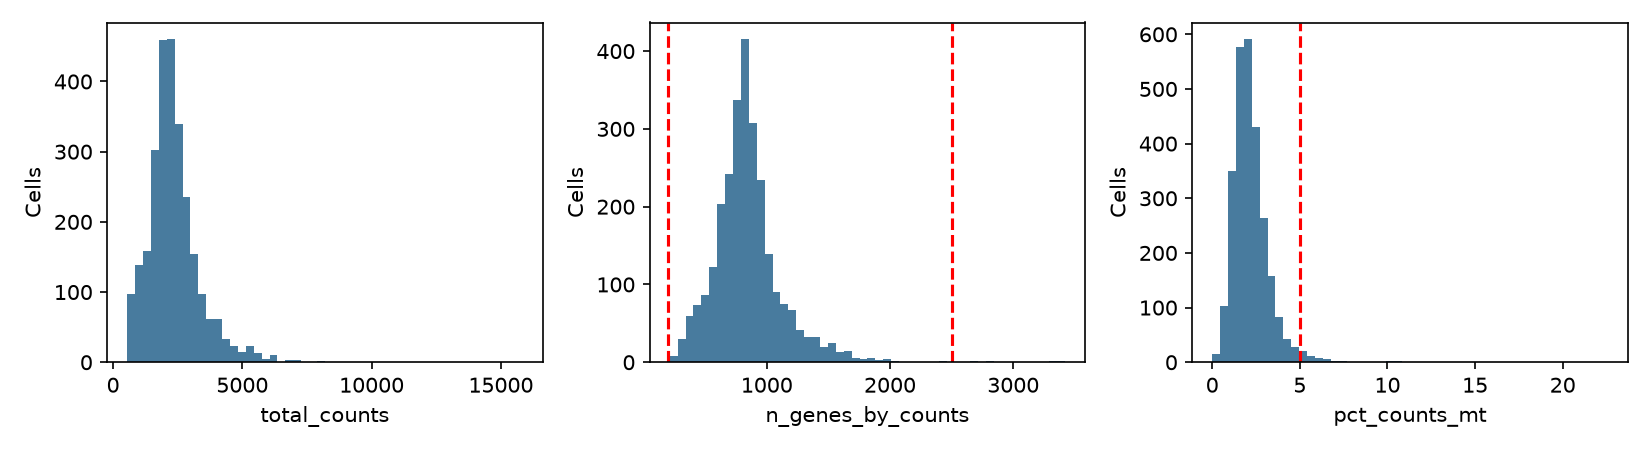

,stage,cells,genes
0,raw counts,2700,32738
1,cell QC,2638,32738


In [3]:
qc = raw.copy()
qc.var["mt"] = qc.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(qc, qc_vars=["mt"], percent_top=None, inplace=True)
columns = ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
display(qc.obs[columns].describe(percentiles=[.01, .5, .99]))
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, column in zip(axes, columns):
    ax.hist(qc.obs[column], bins=50, color="#487b9e")
    ax.set(xlabel=column, ylabel="Cells")
axes[1].axvline(config.min_genes, color="red", linestyle="--")
axes[1].axvline(config.max_genes, color="red", linestyle="--")
axes[2].axvline(config.max_pct_mt, color="red", linestyle="--")
fig.tight_layout()
fig.savefig(FIGURES / "qc.png", dpi=150)
display(Image(filename=str(FIGURES / "qc.png")))
plt.close(fig)
adata = quality_control(raw, config)
steps = [{"stage": "raw counts", "cells": raw.n_obs, "genes": raw.n_vars},
         {"stage": "cell QC", "cells": adata.n_obs, "genes": adata.n_vars}]
display(pd.DataFrame(steps))

## 3. 保留 counts，正規化，再取 log1p

先移除少於 3 個細胞偵測到的基因，並把 counts 複製到 `layers['counts']`。`normalize_total` 使每個細胞的總量縮放到 10,000；`log1p(x) = log(1+x)` 壓縮較大的表達值。這些處理後的數值不再是原始 RNA counts。

此處是全資料探索。模型另在切分之後僅用 train 選基因，且在基因子集前使用全 library 正規化，詳見 Notebook 02。

In [4]:
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata)
steps.append({"stage": "gene filter / normalize / log1p", "cells": adata.n_obs, "genes": adata.n_vars})
display(pd.DataFrame(steps))
print("相同位置的原始 counts:")
display(adata[:3, -6:].to_df(layer="counts"))
print("處理後的 log1p 表達值:")
display(adata[:3, -6:].to_df())

,stage,cells,genes
0,raw counts,2700,32738
1,cell QC,2638,32738
2,gene filter / normalize / log1p,2638,13656


相同位置的原始 counts:


index,MT-CYB,AC145212.1,AL592183.1,AL354822.1,PNRC2-1,SRSF10-1
index,,,,,,
AAACATACAACCAC-1,4.0,0.0,0.0,0.0,0.0,0.0
AAACATTGAGCTAC-1,8.0,0.0,1.0,0.0,0.0,0.0
AAACATTGATCAGC-1,4.0,0.0,0.0,0.0,0.0,0.0


處理後的 log1p 表達值:


index,MT-CYB,AC145212.1,AL592183.1,AL354822.1,PNRC2-1,SRSF10-1
index,,,,,,
AAACATACAACCAC-1,2.864242,0.0,0.000000,0.0,0.0,0.0
AAACATTGAGCTAC-1,2.851662,0.0,1.111715,0.0,0.0,0.0
AAACATTGATCAGC-1,2.618163,0.0,0.000000,0.0,0.0,0.0


## 4. 特徵選擇、PCA 與 UMAP

探索時選約 2,000 個 highly variable genes（HVGs），以 30 個 PCA 成分建立鄰居圖，再用 UMAP 投影到平面。顏色只表示粒線體 counts 比例，不是 cell type。

UMAP 用來視覺化鄰近關係；圖上的分群不是獨立標籤，也不是生物機制或因果證據。

探索用 HVGs: 2000


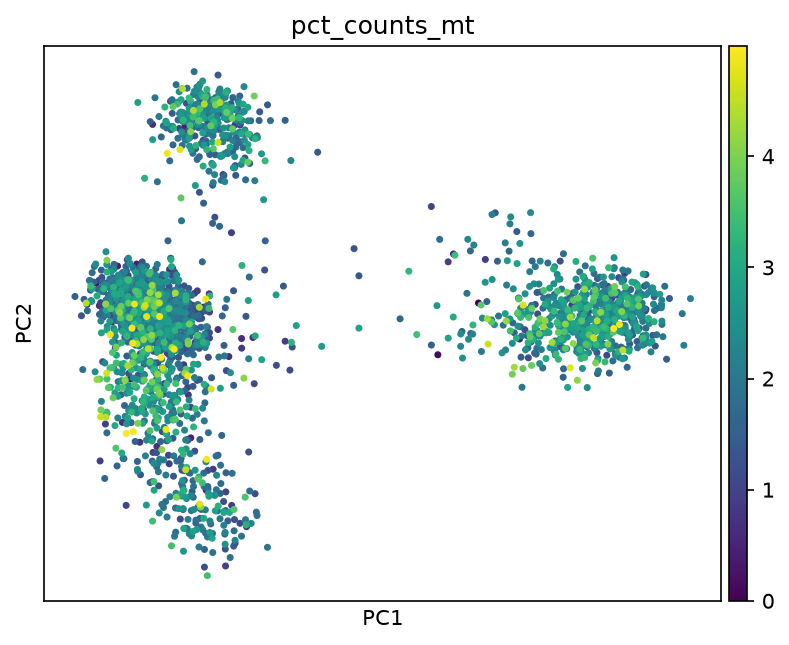

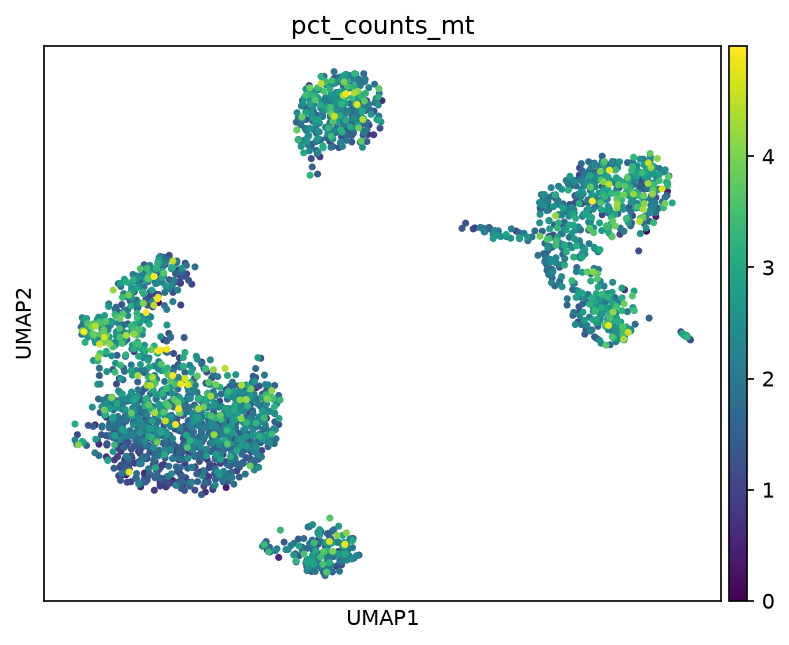

PCA shape: (2638, 30) UMAP shape: (2638, 2)


In [5]:
sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000)
print("探索用 HVGs:", int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=30, mask_var="highly_variable", random_state=42)
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=30, random_state=42)
sc.tl.umap(adata, random_state=42)
for basis in ["pca", "umap"]:
    fig = getattr(sc.pl, basis)(adata, color="pct_counts_mt", show=False, return_fig=True)
    fig.savefig(FIGURES / f"{basis}.png", dpi=150, bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{basis}.png")))
    plt.close(fig)
print("PCA shape:", adata.obsm["X_pca"].shape, "UMAP shape:", adata.obsm["X_umap"].shape)

## 5. 儲存並回顧

`X` 現在是 log1p 表達值；`layers['counts']` 保留相同細胞／基因的原始計數；`obsm` 儲存 PCA／UMAP 座標。原始下載檔始終保留。

請嘗試說明：一筆樣本是什麼？一個 feature 是什麼？為何不能把 UMAP 群集直接當成真實 cell-type 標籤？

In [6]:
import json
from dataclasses import asdict
processed = ROOT / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)
adata.write_h5ad(processed / "exploration.h5ad", compression="gzip")
metrics = ROOT / "outputs" / "metrics"
metrics.mkdir(parents=True, exist_ok=True)
report = {"steps": steps, "qc_config": asdict(config), "seed": 42,
          "note": "Full-data exploration; not model training inputs."}
(metrics / "notebook_exploration.json").write_text(json.dumps(report, indent=2) + "\n")
display(pd.DataFrame(steps))

,stage,cells,genes
0,raw counts,2700,32738
1,cell QC,2638,32738
2,gene filter / normalize / log1p,2638,13656
